# IRIS — Monthly Forecast BTC (30 hari, resolusi harian)

**Penanggung jawab:** Timothy · **Bagian:** Monthly forecasting · **Metode:** Monte Carlo *Filtered Historical Simulation* (FHS) + GARCH(1,1), volatilitas awal dari implied volatility Deribit (DVOL)

Notebook ini **tidak menyalin kode model**. Semua perhitungan memanggil modul yang sama dengan pipeline produksi (`worker/iris_worker/`), sehingga angka di sini identik dengan yang ditulis worker mingguan ke Supabase dan ditampilkan di dashboard `/forecast/monthly`.

**Isi notebook**
1. Data harga BTC & DVOL
2. Model volatilitas (GARCH vs DVOL × VRP)
3. Forecast 30 hari: fan chart Monte Carlo + tabel band harian
4. Backtest out-of-sample: coverage, pinball loss, PIT, coverage per tahun
5. Error titik (MAPE) dan cara membacanya
6. Uji leakage pada data asli
7. Riset pendukung: kenapa bukan XGBoost, kandidat perbaikan, uji DVOL
8. Kesimpulan & batasan

## 0. Setup

`USE_LIVE_DATA = False` memakai CSV di `notebooks/data/` (reproducible, dipakai untuk menjalankan notebook ini).
Set `True` untuk mengambil data terbaru: harga dari Coinbase → Yahoo → Kraken, DVOL dari Deribit. Beberapa ISP Indonesia memblokir Coinbase/Kraken/Deribit — **Google Colab atau GitHub Actions** bisa mengaksesnya.

In [1]:
import sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker

# notebook ada di worker/notebooks/ -> modul worker satu folder di atas
WORKER = Path.cwd().parent if (Path.cwd().parent / "iris_worker").exists() else Path.cwd()
sys.path.insert(0, str(WORKER))

from iris_worker.prices import csv_daily, load_daily
from iris_worker import dvol as dvol_mod
from iris_worker.garch import fit_garch11
from iris_worker.monthly import build_run
from iris_worker.backtest import run_backtest

USE_LIVE_DATA = False
DATA = WORKER / "notebooks" / "data"
HORIZON, N_PATHS, BACKTEST_PATHS = 30, 10_000, 1_000

# gaya grafik: surface terang, tinta netral, satu urutan warna kategorikal yang tetap
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "figure.dpi": 110,
})
usd = mticker.FuncFormatter(lambda v, _: f"${v/1000:,.0f}k")

## 1. Data

In [2]:
if USE_LIVE_DATA:
    series = load_daily()
    dvol_by_date = dvol_mod.fetch_dvol()
else:
    series = csv_daily(str(DATA / "btc_daily_close.csv"))
    dvol_by_date = dvol_mod.load_dvol_csv(str(DATA / "dvol_btc_daily.csv"))

px = pd.Series(series.closes, index=pd.to_datetime(series.dates), name="close")
dv = pd.Series(dvol_by_date).sort_index(); dv.index = pd.to_datetime(dv.index)
print(f"Harga BTC : {len(px):,} hari  {px.index[0].date()} → {px.index[-1].date()}  (sumber: {series.source.split(':')[0]})")
print(f"DVOL      : {len(dv):,} hari  {dv.index[0].date()} → {dv.index[-1].date()}")
print(f"Tanggal hilang di harga: {int((px.index.to_series().diff().dt.days != 1).sum() - 1)}")

Harga BTC : 4,185 hari  2015-03-08 → 2026-08-21  (sumber: csv)
DVOL      : 2,035 hari  2021-03-24 → 2026-10-18
Tanggal hilang di harga: 0


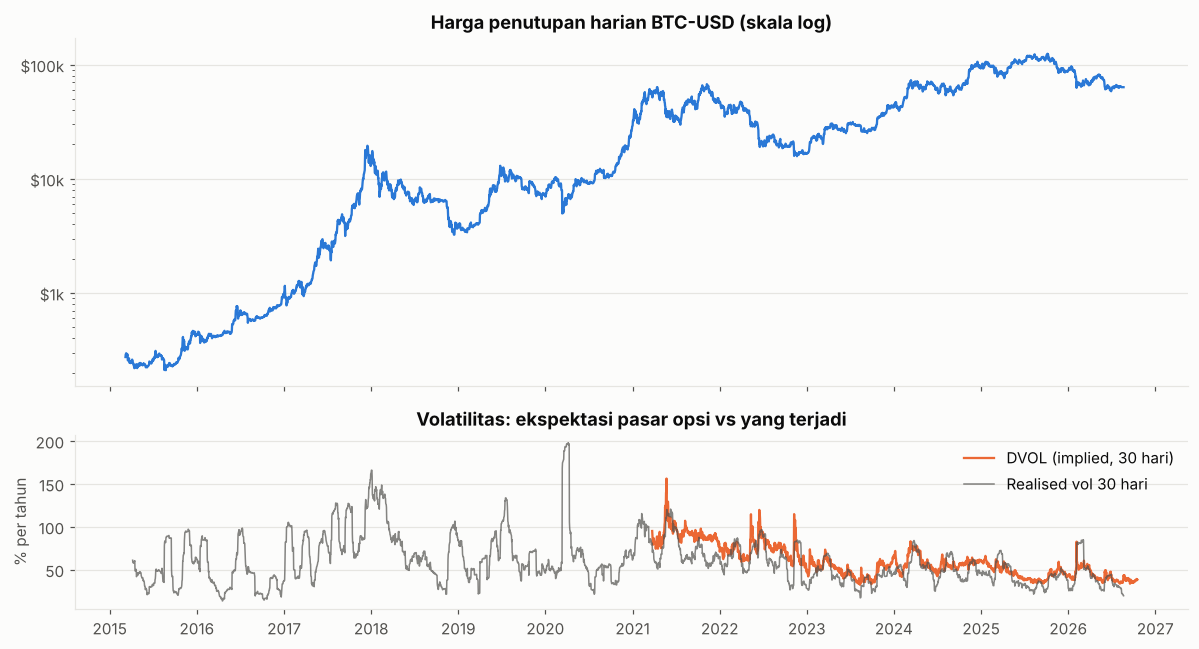

In [3]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(px.index, px, color=BLUE, lw=1.5)
a1.set_yscale("log"); a1.yaxis.set_major_formatter(usd); a1.set_title("Harga penutupan harian BTC-USD (skala log)")
a2.plot(dv.index, dv, color=ORANGE, lw=1.5, label="DVOL (implied, 30 hari)")
rv30 = np.log(px).diff().rolling(30).std() * np.sqrt(365) * 100
a2.plot(rv30.index, rv30, color=INK2, lw=1, alpha=.7, label="Realised vol 30 hari")
a2.set_ylabel("% per tahun"); a2.set_title("Volatilitas: ekspektasi pasar opsi vs yang terjadi")
a2.legend(frameon=False, loc="upper right")
a2.xaxis.set_major_locator(mdates.YearLocator()); a2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

## 2. Model volatilitas

Arah harga 30 hari tidak bisa ditebak (bagian 7), tetapi **volatilitas bisa**: periode bergejolak cenderung diikuti periode bergejolak.

- **GARCH(1,1)** memodelkan volatilitas bersyarat dan kembali perlahan ke rata-rata jangka panjang.
- **DVOL** adalah ekspektasi volatilitas 30 hari dari pasar opsi Deribit (informasi ke depan yang tidak ada di riwayat harga). DVOL biasanya di atas volatilitas yang terjadi (*variance risk premium*), jadi dikalikan faktor **VRP** = median(realised/implied) dari jendela 30 hari yang **sudah selesai**.
- Simulasi: residual GARCH terstandar di-*resample* (FHS), 10.000 jalur, volatilitas tiap jalur berkembang lewat rekursi GARCH-nya sendiri. **Drift dibuang**, jadi median ≈ harga sekarang — model ini tentang *seberapa jauh*, bukan *ke mana*.

In [4]:
log_ret = np.diff(np.log(np.asarray(series.closes)))
fit = fit_garch11(log_ret - log_ret.mean())
sig = dvol_mod.align(series.dates, dvol_by_date)
start = dvol_mod.start_sigma(sig, dvol_mod.realised_windows(log_ret), len(log_ret))
ann = lambda s: s * np.sqrt(365) * 100

rows = [
    ("alpha (reaksi ke shock)", f"{fit.alpha:.3f}"),
    ("beta (persistensi)", f"{fit.beta:.3f}"),
    ("alpha + beta", f"{fit.persistence:.3f}"),
    ("Vol GARCH saat ini", f"{ann(fit.last_sigma):.1f}% / tahun"),
    ("Vol jangka panjang", f"{ann(fit.long_run_sigma):.1f}% / tahun"),
]
if start:
    rows += [("DVOL (as-of)", f"{ann(start[1]):.1f}% / tahun"),
             ("Faktor VRP", f"{start[2]:.3f}"),
             ("Vol awal yang dipakai = DVOL × VRP", f"{ann(start[0]):.1f}% / tahun")]
pd.DataFrame(rows, columns=["Parameter", "Nilai"]).set_index("Parameter")

,Nilai
Parameter,
alpha (reaksi ke shock),0.110
beta (persistensi),0.850
alpha + beta,0.960
Vol GARCH saat ini,34.8% / tahun
Vol jangka panjang,65.8% / tahun
DVOL (as-of),43.3% / tahun
Faktor VRP,0.792
Vol awal yang dipakai = DVOL × VRP,34.3% / tahun


## 3. Forecast 30 hari

`build_run` adalah fungsi yang sama yang dijalankan scheduler setiap Senin: simulasi, backtest, lalu menyiapkan baris untuk Supabase.

In [5]:
t0 = time.time()
run = build_run(series, HORIZON, N_PATHS, True, BACKTEST_PATHS, 120, 24, dvol_by_date=dvol_by_date)
bt = run["backtest"]; m = run["model"]
print(f"selesai dalam {time.time()-t0:.1f} detik · engine: {run['method']} · as-of {run['as_of']} · spot ${run['spot']:,.0f}")

selesai dalam 3.7 detik · engine: fhs_dvol · as-of 2026-08-21 · spot $63,552


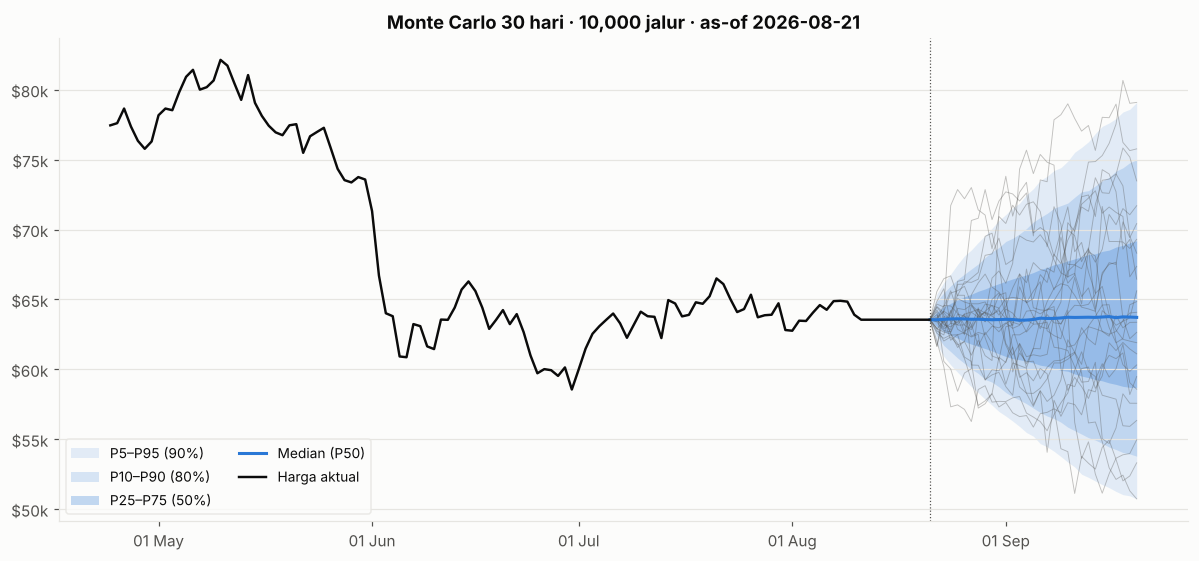

Garis abu-abu tipis = 24 jalur simulasi asli yang dipilih merata dari P5 sampai P95 (ilustrasi sebaran, bukan prediksi).


In [6]:
bands = pd.DataFrame(run["bands"]); bands["date"] = pd.to_datetime(bands["date"])
hist = pd.DataFrame(run["history"]); hist["date"] = pd.to_datetime(hist["date"])
paths = np.array(run["paths"])

fig, ax = plt.subplots(figsize=(11, 5.2))
for lo, hi, a, lab in (("p5", "p95", .12, "P5–P95 (90%)"), ("p10", "p90", .18, "P10–P90 (80%)"), ("p25", "p75", .28, "P25–P75 (50%)")):
    ax.fill_between(bands["date"], bands[lo], bands[hi], color=BLUE, alpha=a, lw=0, label=lab)
for p in paths:
    ax.plot(bands["date"], p, color=INK2, lw=.6, alpha=.35)
ax.plot(bands["date"], bands["p50"], color=BLUE, lw=2, label="Median (P50)")
ax.plot(hist["date"], hist["close"], color=INK, lw=1.6, label="Harga aktual")
ax.axvline(bands["date"].iloc[0], color=INK2, lw=.8, ls=":")
ax.yaxis.set_major_formatter(usd)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_title(f"Monte Carlo 30 hari · {N_PATHS:,} jalur · as-of {run['as_of']}")
ax.legend(frameon=True, facecolor=SURF, edgecolor=GRID, loc="lower left", ncol=2, fontsize=9)
plt.tight_layout(); plt.show()
print("Garis abu-abu tipis = 24 jalur simulasi asli yang dipilih merata dari P5 sampai P95 (ilustrasi sebaran, bukan prediksi).")

In [7]:
spot = run["spot"]
ladder = bands.set_index("step").loc[[1, 7, 14, 21, 30], ["date", "p5", "p10", "p25", "p50", "p75", "p90", "p95"]]
ladder["date"] = ladder["date"].dt.date
show = ladder.copy()
for c in ["p5", "p10", "p25", "p50", "p75", "p90", "p95"]:
    show[c] = [f"${v:,.0f} ({(v/spot-1)*100:+.1f}%)" for v in ladder[c]]
show.index = [f"D+{i}" for i in show.index]
show

,date,p5,p10,p25,p50,p75,p90,p95
D+1,2026-08-22,"$61,780 (-2.8%)","$62,399 (-1.8%)","$63,067 (-0.8%)","$63,549 (-0.0%)","$64,088 (+0.8%)","$64,856 (+2.1%)","$65,404 (+2.9%)"
D+7,2026-08-28,"$58,324 (-8.2%)","$59,711 (-6.0%)","$61,650 (-3.0%)","$63,586 (+0.1%)","$65,588 (+3.2%)","$67,541 (+6.3%)","$69,078 (+8.7%)"
D+14,2026-09-04,"$55,480 (-12.7%)","$57,544 (-9.5%)","$60,581 (-4.7%)","$63,528 (-0.0%)","$66,759 (+5.0%)","$70,070 (+10.3%)","$72,489 (+14.1%)"
D+21,2026-09-11,"$53,017 (-16.6%)","$55,615 (-12.5%)","$59,667 (-6.1%)","$63,714 (+0.3%)","$67,902 (+6.8%)","$72,312 (+13.8%)","$75,531 (+18.8%)"
D+30,2026-09-20,"$50,736 (-20.2%)","$53,791 (-15.4%)","$58,708 (-7.6%)","$63,719 (+0.3%)","$69,199 (+8.9%)","$74,988 (+18.0%)","$79,097 (+24.5%)"


In [8]:
prob = pd.DataFrame(m["probabilities"])[["label", "price", "prob_above"]]
prob.columns = ["Perubahan", "Harga", "P(harga D+30 ≥ level)"]
prob["Harga"] = prob["Harga"].map(lambda v: f"${v:,.0f}")
prob["P(harga D+30 ≥ level)"] = prob["P(harga D+30 ≥ level)"].map(lambda v: f"{v:.0%}")
prob.set_index("Perubahan")

,Harga,P(harga D+30 ≥ level)
Perubahan,,
-30%,"$44,486",98%
-20%,"$50,842",95%
-10%,"$57,197",81%
0%,"$63,552",51%
+10%,"$69,907",22%
+20%,"$76,262",8%
+30%,"$82,617",3%


## 4. Backtest out-of-sample

Setiap minggu sejak data cukup, model membuat forecast **hanya dengan data sebelum tanggal itu** (GARCH di-refit tiap tahun pada jendela yang membesar; DVOL dan faktor VRP juga hanya dari masa lalu), lalu dinilai terhadap harga yang benar-benar terjadi 7, 14, dan 30 hari kemudian. Semua metode dinilai pada **tanggal yang sama**.

- **Coverage P10–P90**: seberapa sering harga asli jatuh di dalam band 80% → ideal **80%**, bukan makin tinggi makin bagus.
- **Pinball loss**: skor utama untuk forecast kuantil → **makin kecil makin baik**, tidak bisa diakali dengan melebarkan band.
- **INDEP.**: jumlah jendela yang tidak tumpang tindih — ukuran sampel yang sebenarnya.

In [9]:
NAMES = {"fhs": "FHS (GARCH)", "fhs_dvol": "FHS + DVOL ★ dipakai", "fhs_cal": "FHS + kalibrasi (ditolak)",
         "iid": "Bootstrap i.i.d.", "garch_normal": "GARCH + Normal"}
rows = []
for h in bt["horizons"]:
    for x in h["methods"]:
        rows.append({"Horizon": f"{h['h']} hari", "Metode": NAMES[x["method"]],
                     "Coverage P25–75 (50%)": x["coverage"]["50"], "Coverage P10–90 (80%)": x["coverage"]["80"],
                     "Coverage P5–95 (90%)": x["coverage"]["90"], "Pinball ↓": x["pinball"],
                     "Miss atas": x["upper_miss"], "Miss bawah": x["lower_miss"], "Indep.": h["independent"]})
tbl = pd.DataFrame(rows).set_index(["Horizon", "Metode"])
print(f"{bt['origins']} titik uji mingguan · {bt['first_origin']} → {bt['last_origin']} · {bt['warmup_origins']} titik awal dikeluarkan (warm-up)")
pct = ["Coverage P25–75 (50%)", "Coverage P10–90 (80%)", "Coverage P5–95 (90%)", "Miss atas", "Miss bawah"]
best = tbl.groupby(level=0)["Pinball ↓"].transform("min") == tbl["Pinball ↓"]
(tbl.style.format({**{c: "{:.1%}" for c in pct}, "Pinball ↓": "{:.4f}"})
    .apply(lambda col: ["font-weight:bold; background:#e8f1fc" if b else "" for b in best], subset=["Pinball ↓"]))

261 titik uji mingguan · 2021-07-22 → 2026-07-16 · 124 titik awal dikeluarkan (warm-up)


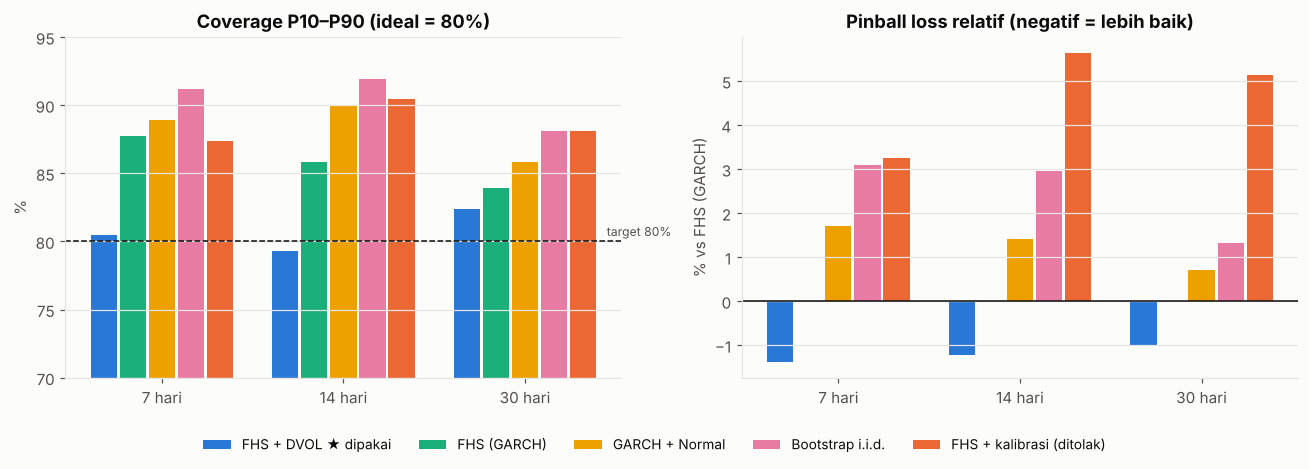

In [10]:
order = ["fhs_dvol", "fhs", "garch_normal", "iid", "fhs_cal"]
colors = {"fhs_dvol": BLUE, "fhs": AQUA, "garch_normal": YELLOW, "iid": MAGENTA, "fhs_cal": ORANGE}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
hs = [h["h"] for h in bt["horizons"]]; w = .16
for i, k in enumerate(order):
    cov = [next(x for x in h["methods"] if x["method"] == k)["coverage"]["80"] * 100 for h in bt["horizons"]]
    base = [next(x for x in h["methods"] if x["method"] == "fhs")["pinball"] for h in bt["horizons"]]
    pin = [(next(x for x in h["methods"] if x["method"] == k)["pinball"] / b - 1) * 100 for h, b in zip(bt["horizons"], base)]
    xs = np.arange(len(hs)) + (i - 2) * w
    axes[0].bar(xs, cov, w * .9, color=colors[k], label=NAMES[k])
    axes[1].bar(xs, pin, w * .9, color=colors[k])
axes[0].axhline(80, color=INK, lw=1, ls="--"); axes[0].text(2.45, 80.4, "target 80%", fontsize=8, color=INK2)
axes[0].set_ylim(70, 95); axes[0].set_ylabel("%"); axes[0].set_title("Coverage P10–P90 (ideal = 80%)")
axes[1].axhline(0, color=INK, lw=1); axes[1].set_ylabel("% vs FHS (GARCH)"); axes[1].set_title("Pinball loss relatif (negatif = lebih baik)")
for a in axes:
    a.set_xticks(range(len(hs))); a.set_xticklabels([f"{h} hari" for h in hs])
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, fontsize=9, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

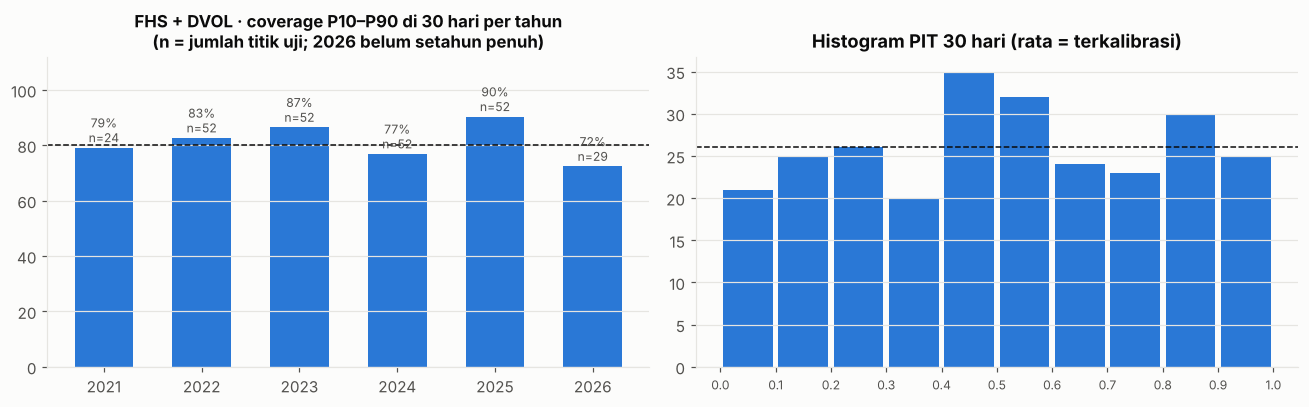

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
yrs = pd.DataFrame(bt["fhs_dvol_coverage80_by_year_h30"])
axes[0].bar(yrs["year"], yrs["coverage"] * 100, color=BLUE, width=.6)
axes[0].axhline(80, color=INK, lw=1, ls="--")
for x_, y_, n_ in zip(yrs["year"], yrs["coverage"] * 100, yrs["origins"]):
    axes[0].text(x_, y_ + 2, f"{y_:.0f}%\nn={n_}", ha="center", fontsize=8, color=INK2)
axes[0].set_ylim(0, 112); axes[0].set_title("FHS + DVOL · coverage P10–P90 di 30 hari per tahun\n(n = jumlah titik uji; 2026 belum setahun penuh)", fontsize=11)

h30 = next(h for h in bt["horizons"] if h["h"] == 30)
pit = next(x for x in h30["methods"] if x["method"] == "fhs_dvol")["pit"]
axes[1].bar(np.arange(10) + .5, pit, width=.9, color=BLUE)
axes[1].axhline(sum(pit) / 10, color=INK, lw=1, ls="--")
axes[1].set_xticks(range(0, 11)); axes[1].set_xticklabels([f"{i/10:.1f}" for i in range(11)], fontsize=8)
axes[1].set_title("Histogram PIT 30 hari (rata = terkalibrasi)")
plt.tight_layout(); plt.show()

## 5. Error titik (MAPE)

MAPE median = rata-rata selisih persen antara median forecast dan harga yang terjadi. Karena drift dibuang, median ≈ harga hari ini, sehingga **MAPE model sama dengan tebakan naif “harga tidak berubah”**. Angka ini mengukur **seberapa jauh BTC bergerak**, bukan kualitas model; yang membedakan metode adalah coverage dan pinball.

In [12]:
rows = []
for h in bt["horizons"]:
    x = next(x for x in h["methods"] if x["method"] == "fhs_dvol")
    rows.append({"Horizon": f"{h['h']} hari", "MAPE median (FHS+DVOL)": x["mape_median"],
                 "MAPE naif (harga tetap)": h["naive_mape"], "Median APE": x["median_ape_median"],
                 "Lebar rata-rata P10–P90": x["width80_pct"], "Coverage P10–P90": x["coverage"]["80"]})
pd.DataFrame(rows).set_index("Horizon").style.format("{:.2%}")

,MAPE median (FHS+DVOL),MAPE naif (harga tetap),Median APE,Lebar rata-rata P10–P90,Coverage P10–P90
Horizon,,,,,
7 hari,5.22%,5.19%,3.79%,16.14%,80.46%
14 hari,7.62%,7.61%,5.63%,24.67%,79.31%
30 hari,11.75%,11.68%,9.50%,40.15%,82.38%


## 6. Uji leakage pada data asli

Seluruh harga dan DVOL setelah titik potong diganti dengan data acak yang sangat berbeda. Kalau tidak ada kebocoran, skor semua titik uji yang hasilnya sudah selesai **sebelum** titik potong harus **identik**. (Versi sintetis uji ini juga dijalankan di setiap run lewat `pytest`.)

In [13]:
r = log_ret
cut = len(r) - 400
kw = dict(horizons=(7, 14, 30), n_paths=300, return_records=True)
a = run_backtest(r, series.dates[1:], dvol_sigma=sig, **kw)
r2 = r.copy(); r2[cut:] = np.random.default_rng(0).standard_normal(len(r) - cut) * 0.08
dv2 = {d: (v * 3 if d > series.dates[cut] else v) for d, v in dvol_by_date.items()}
b = run_backtest(r2, series.dates[1:], dvol_sigma=dvol_mod.align(series.dates, dv2), **kw)
rb = {x["t"]: x for x in b["records"]}
early = [x for x in a["records"] if x["t"] + 30 <= cut]
late = [x for x in a["records"] if x["t"] > cut]
same = sum(x["scores"] == rb[x["t"]]["scores"] for x in early)
moved = sum(x["scores"] != rb[x["t"]]["scores"] for x in late)
print(f"Titik potong: {series.dates[cut]}")
print(f"Titik uji sebelum potong : {same}/{len(early)} identik  → {'LOLOS: tidak ada leakage' if same == len(early) else 'GAGAL'}")
print(f"Titik uji setelah potong : {moved}/{len(late)} berubah (uji tidak kosong)")

Titik potong: 2025-07-17
Titik uji sebelum potong : 204/204 identik  → LOLOS: tidak ada leakage
Titik uji setelah potong : 52/52 berubah (uji tidak kosong)


## 7. Riset pendukung

### 7a. Kenapa bukan XGBoost (model arah)
Model awal: XGBoost quantile regression (Q10/Q50/Q90 return 30 hari) dengan fitur harga, teknikal, makro FRED, dan on-chain, walk-forward 5 fold pada `btc_master_2`. Hasil (dari `research/benchmark_xgb_vs_baselines.py`, butuh dataset fitur lengkap):

| Model | Pinball ↓ | Coverage P10–P90 per fold | Akurasi arah median |
|---|---|---|---|
| XGB harga + kalender | 0.053 | 68–92% | 48% |
| XGB + teknikal | 0.050 | 63–91% | 48% |
| XGB fitur stasioner + purge | 0.048 | 57–95% | 54% |
| Kuantil historis konstan (tanpa fitur) | **0.045** | 75–91% | 54% |
| Volatility-scaled, median 0 | 0.048 | **73–84%** | — |

Tidak ada set fitur yang mengalahkan baseline konstan, dan akurasi arah tidak lebih baik dari tebakan “selalu naik” (54%). **Volatilitas bisa diprediksi, arah 30 hari tidak** — maka model akhir fokus ke range.

### 7b. Delapan kandidat perbaikan berbasis harga (validasi → test)
Protokol: kandidat ditentukan dulu, pemenang dipilih di validasi (2020–2022), diuji **sekali** di test (2023–2026) dengan uji Diebold–Mariano.

In [14]:
import contextlib, io, runpy
def run_script(name, *args):
    buf = io.StringIO()
    argv = sys.argv
    sys.argv = [name, *args]
    try:
        with contextlib.redirect_stdout(buf):
            runpy.run_path(str(WORKER / "research" / name), run_name="__main__")
    finally:
        sys.argv = argv
    print(buf.getvalue())

run_script("improve_monthly.py", str(DATA / "btc_daily_close.csv"))

origins: validation 144 (2020-04-01..2023-01-01), test 185 (2023-01-01..)

VALIDATION — pinball relative to fhs_base (negative = better), and P10–P90 coverage
candidate         7d rel   7d cov   14d rel  14d cov   30d rel  30d cov  mean rel
fhs_base          +0.00%    81.9%    +0.00%    75.7%    +0.00%    70.8%    +0.00%
fhs_refit28       +0.21%    81.9%    -0.07%    75.7%    -0.56%    70.8%    -0.14%
fhs_pool3y        +0.16%    84.0%    -0.06%    78.5%    +0.36%    72.9%    +0.15%
fhs_volblend      +0.61%    81.2%    +0.64%    75.7%    +0.33%    71.5%    +0.52%
fhs_drift25       -0.18%    81.9%    -0.27%    76.4%    -0.70%    70.8%    -0.38%
fhs_drift50       -0.18%    81.2%    -0.42%    77.1%    -0.88%    72.2%    -0.49%
garch_n           +1.09%    84.0%    +0.01%    79.9%    -1.06%    74.3%    +0.01%
ens_fhs_gn        +0.39%    84.0%    -0.11%    77.8%    -0.65%    72.9%    -0.12%
ens3              -0.26%    84.7%    -0.62%    79.9%    -1.10%    72.2%    -0.66%

winner on validation

Pemenang validasi justru **lebih buruk** di test (signifikan di 7 & 14 hari): kesalahan model berbalik arah antar rezim (terlalu sempit 2020–22, terlalu lebar 2023–26). Dengan input harga saja, model sudah di batasnya → butuh informasi baru.

### 7c. Implied volatility (DVOL) — protokol yang sama

In [15]:
run_script("dvol_monthly.py", str(DATA / "btc_daily_close.csv"), str(DATA / "dvol_btc_daily.csv"))

origins: validation 76 (2021-07-22..2022-12-29), test 185 (2023-01-05..2026-07-16)

VALIDATION — pinball vs fhs_base (negative = better) and P10–P90 coverage
candidate         7d rel   7d cov   14d rel  14d cov   30d rel  30d cov  mean rel
fhs_base          +0.00%    88.2%    +0.00%    80.3%    +0.00%    80.3%    +0.00%
fhs_dvol          +1.22%    89.5%    +1.81%    89.5%    +0.14%    81.6%    +1.05%
fhs_dvol_vrp      -1.79%    84.2%    -0.51%    78.9%    +0.04%    77.6%    -0.75%
fhs_blend         -0.92%    88.2%    -0.36%    81.6%    -0.03%    78.9%    -0.44%
gn_dvol_vrp       -1.06%    85.5%    +0.73%    78.9%    +1.94%    72.4%    +0.53%
ens_base_gn       -0.66%    86.8%    +0.01%    80.3%    +0.59%    76.3%    -0.02%

winner on validation: fhs_dvol_vrp (-0.75%)

TEST (scored once) — winner vs fhs_base, Diebold–Mariano, Newey–West lag = h/step
  h  base pin   win pin      rel  base cov  win cov    DM t      p
  7    0.0149    0.0147   -1.54%     87.0%    77.8%    1.25  0.210
 14   

**FHS + DVOL × VRP** adalah kandidat pertama yang keunggulannya di validasi **bertahan di test**, searah di ketiga horizon (pinball −1.2% s/d −1.5%). Belum signifikan di α = 5% (periode test ±3,5 tahun), tetapi uji kalibrasi Kupiec pada 7 hari menolak model lama (band terlalu lebar) dan tidak menolak model DVOL. Model ini yang dipakai di produksi; bila DVOL gagal diambil, worker otomatis kembali ke GARCH.

## 8. Kesimpulan & batasan

**Hasil**
- Forecast range 30 hari harian dengan band P5–P95, diperbarui otomatis setiap Senin (GitHub Actions → Supabase → dashboard).
- Band P10–P90 terkalibrasi (~80%) di 7/14/30 hari dan pinball loss terkecil dibanding semua pembanding.
- Evaluasi bebas leakage (diuji otomatis), semua pilihan model lewat protokol validasi → test.

**Batasan**
- Model memprediksi **range, bukan arah**. MAPE median (≈5% / 7% / 12%) sama dengan tebakan naif; arah ditangani komponen weekly & sentimen IRIS.
- Peningkatan dari DVOL konsisten tetapi belum signifikan secara statistik; track record live akan memperkuat atau membantah seiring waktu.
- Range lebar (90%: kira-kira −20% s/d +25% di 30 hari) karena BTC memang bergerak sebesar itu; tampilkan P25–P75 sebagai “range paling mungkin”.

**Reproduksi**: `pip install -r worker/requirements.txt pandas matplotlib`, buka notebook ini dari folder `worker/notebooks/`, jalankan semua sel. Detail keputusan: `docs/DECISIONS.md` §4.